## understanding variablity in historical period (1900 - 2014) using observations and historical simulations from SMILEs and CMIP data archive

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [3]:
from scipy import stats

In [4]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [6]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [7]:
from functions import preproc_funcs as funcs

In [8]:
from functions import xr_lowess

### load data

In [9]:
precip_obs = xr.open_mfdataset('/g/data/ob22/as8561/data/obs_local/gpcc_v2020/precip.mon.total.1x1.v2020.nc').precip.load()
precip_obs

<xarray.DataArray 'precip' (time: 1548, lat: 180, lon: 360)>
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)
Coordinates:
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 355.5 356.5 357.5 358.5 359.5
  * time     (time) datetime64[ns] 1891-01-01 1891-02-01 ... 2019-12-01
Attributes:
    long_name:     GPCC Monthly total of precipitation
    statistic:     Total
    valid_range:   [   0. 8000.]
    parent_stat:   Observations
    var_desc:      Precipitation
    units:         mm
    level:         Surface
    dataset:       GPCC Precipitation 1.0degree V2020 Full Reanalysis
    actual_range:  [   0.   4830.39]

In [ ]:
ts_obs_anom = xr.open_dataset('/g/data/ob22/as8561/data/obs_local/HadCRUT.5.0.1.0.analysis.anomalies.ensemble_mean.nc').tas_mean.rename(dict(longitude='lon', latitude='lat'))
ts_obs_anom

<xarray.DataArray 'tas_mean' (time: 2079, lat: 36, lon: 72)>
[5388768 values with dtype=float64]
Coordinates:
  * time         (time) datetime64[ns] 1850-01-16T12:00:00 ... 2023-03-16T12:...
  * lat          (lat) float64 -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon          (lon) float64 -177.5 -172.5 -167.5 -162.5 ... 167.5 172.5 177.5
    realization  int64 ...
Attributes:
    long_name:     blended air_temperature_anomaly over land with sea_water_t...
    units:         K
    cell_methods:  area: mean (interval: 5.0 degrees_north 5.0 degrees_east) ...

In [11]:
precip_rean = xr.open_dataset('/g/data/ob22/as8561/data/20CR/precip/prate.mon.mean.nc')

In [12]:
sst_obs = xc.open_dataset('/g/data/ob22/as8561/data/obs_local/sst_obs.nc', lon_orient=(0,360)).sst
sst_obs = sst_obs.rename(dict(latitude='lat', longitude='lon'))
sst_obs

<xarray.DataArray 'sst' (time: 1837, lat: 180, lon: 361)>
array([[[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        ...,
...
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. ,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8, -1000. , ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. ,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]]],
      dtype=float32)
Coordinates:
  * time     (time) object 1870-01-16 11:59:59.505615 ... 2023-01-16 12:00:00
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5 359.5
Attributes:
    standard_name:  sea_surface_temperature
    long_name:      sst
    units:          C
    cell_methods:   time: lat: lon: mean

In [13]:
sst_obs_anom = funcs.calc_anom(sst_obs, sst_obs.sel(time = slice('1960', '1990')))
# sst_obs_anom = sst_obs_anom.sel(time = sst_obs_anom.time.dt.month.isin([9,10,11,12,1,2])).resample(time='AS-JUN').mean('time')
sst_obs_anom = sst_obs_anom.resample(time='AS-JUN').mean('time')
weights_sst_obs = np.cos(np.deg2rad(sst_obs.lat))
nino34_obs = funcs.detrend_separate_check(sst_obs_anom.sel(lat=slice(5,-5), lon = slice(-170+360, -120+360)).weighted(weights_sst_obs).mean(('lat', 'lon')), period=15, dim='time')


In [14]:
import seaborn as sns

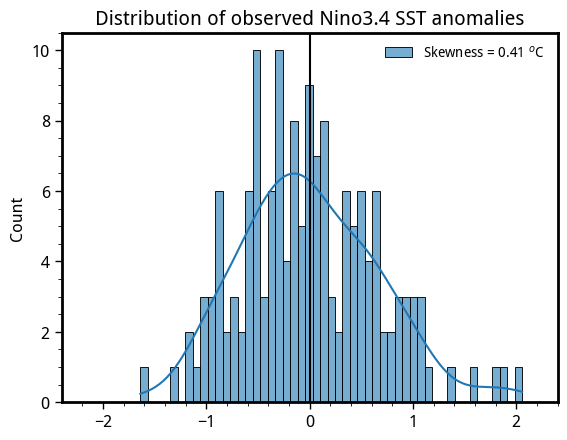

In [15]:
sns.histplot(nino34_obs, bins=51, kde=True, alpha=0.6, color='tab:blue', label=f'Skewness = {np.round(stats.skew(nino34_obs), 3)} $^o$C')
plt.axvline(0.0, color='k', ls='-')
plt.xlim(-2.4, 2.4)
plt.minorticks_on()
plt.title('Distribution of observed Nino3.4 SST anomalies')
plt.legend(frameon=False, fontsize=10)

[Text(1, 0, 'strong-LN'),
 Text(2, 0, 'LN'),
 Text(3, 0, 'NEUT'),
 Text(4, 0, 'EN'),
 Text(5, 0, 'strong-EN')]

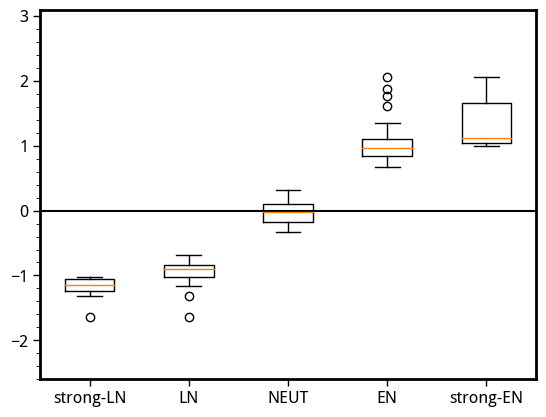

In [16]:
thres = nino34_obs.std('time')
plt.boxplot([nino34_obs.where(nino34_obs < -1.5*thres, drop=True),
             nino34_obs.where(nino34_obs < -thres, drop=True),
             nino34_obs.where((nino34_obs > -0.5*thres) & (nino34_obs < 0.5*thres), drop=True),
             nino34_obs.where(nino34_obs > thres, drop=True),
             nino34_obs.where(nino34_obs > 1.5*thres, drop=True)])


plt.ylim(-2.6, 3.1)
plt.axhline(0.0, color='k', ls='-')
plt.minorticks_on()
plt.tick_params(axis='x', which='minor', bottom=False)
plt.gca().set_xticklabels(['strong-LN', 'LN', 'NEUT', 'EN', 'strong-EN'])

In [17]:
import regionmask

In [18]:
land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(precip_obs)
ar6_mask = regionmask.defined_regions.ar6.land.mask_3D(precip_obs.where(land_mask))

In [19]:
precip_obs_anom = funcs.calc_anom(precip_obs, precip_obs.sel(time = slice('1960', '1990')))
# precip_obs_anom = precip_obs_anom.sel(time = precip_obs_anom.time.dt.month.isin([9,10,11,12,1])).resample(time = 'AS-JUN').mean('time')
precip_obs_anom = precip_obs_anom.resample(time = 'AS-JUN').mean('time')

In [20]:
weights_precip_obs = np.cos(np.deg2rad(precip_obs.lat))
reg_anom = precip_obs_anom.where(ar6_mask.isel(region=15)).weighted(weights_precip_obs).mean(('lat', 'lon'))

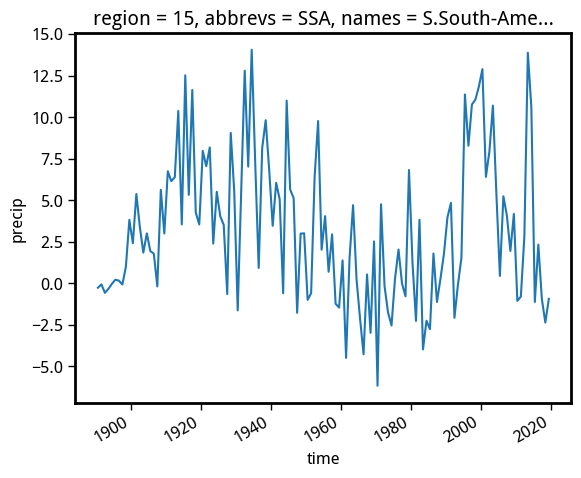

In [21]:
reg_anom.plot()

In [22]:
reg_det = funcs.detrend_separate_check(reg_anom, dim='time', period=15)
reg_std = reg_det/reg_det.std('time')

In [23]:
reg_std = reg_std.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
reg_std['time'] = nino34_obs['time']

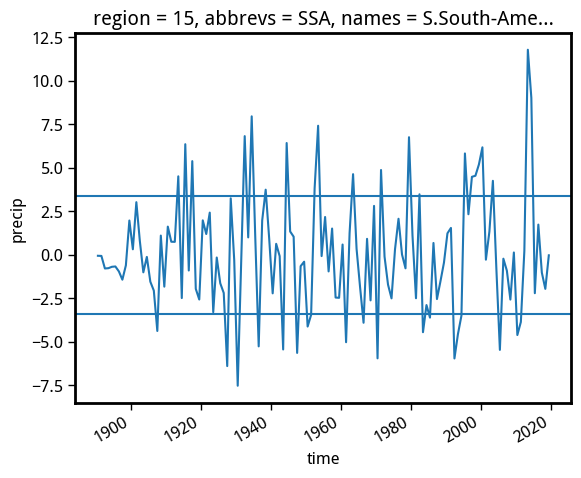

In [24]:
reg_det.plot()
plt.axhline(reg_det.std())
plt.axhline(-reg_det.std())

In [25]:
def calc_tele(precip: xr.DataArray, nino34: xr.DataArray, start_year: int, end_year: int):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    duration = end_year - start_year
    res = stats.linregress(nino34.sel(time=slice(str(start_year), str(end_year))), precip.sel(time=slice(str(start_year), str(end_year))))
    return res.slope, res.pvalue, duration


def get_all_tele(precip: xr.DataArray, nino34: xr.DataArray, initial_dur: int = 10):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    start_years = np.arange(1900, 2016, 2)
    end_years = np.arange(1900, 2016, 2)
    stat = np.empty((len(start_years), len(end_years)))
    pval = np.empty((len(start_years), len(end_years)))
    duration = np.empty((len(start_years), len(end_years)))
    for i in range(len(start_years)):
        for j in range(len(end_years)):
            if end_years[j] < start_years[i] + initial_dur:
                stat[i, j], pval[i, j], duration[i, j] = np.NaN, np.NaN, np.NaN
            else:
                stat[i, j], pval[i, j], duration[i, j] = calc_tele(precip, nino34, start_years[i], end_years[j])
        # print(f"Completed {start_years[i]}", end='\r')
    return start_years, end_years, stat, pval, duration


In [26]:
calc_tele(reg_std, nino34_obs, start_year=1900, end_year=2014)

(0.06377202603112267, 0.6781742930765542, 114)

In [27]:
# reg_std.to_netcdf('./data/eaus_obs.nc')
# nino34_obs.to_netcdf('./data/nino34_obs.nc')

In [28]:
# funcs.get_regr_1d(nino34_obs.sel(time = slice('1900', '2000')), reg_std.sel(time = slice('1900', '2000')))

In [29]:
sy, ey, sl, p, dur = get_all_tele(reg_std, nino34_obs, initial_dur=30)

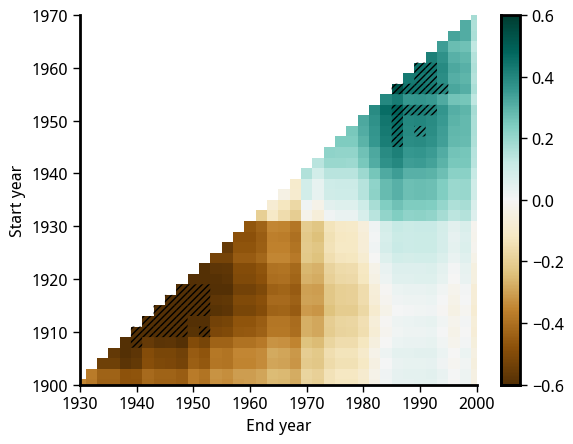

In [30]:
x, y = np.meshgrid(ey, sy)
cf = plt.pcolormesh(ey, sy, sl, cmap='BrBG', vmin=-0.6, vmax=0.6)
z = np.ma.masked_greater(p, 0.05)
plt.pcolor(x,y, z, hatch='/////', alpha=0.)
plt.colorbar(cf)
sns.despine()
# plt.gca().invert_yaxis()
plt.gca().invert_xaxis()
plt.ylabel('Start year')
plt.xlabel('End year')
plt.xlim(1930, 2000)
plt.ylim(1900, 1970)
plt.savefig('./images/method/ssa_reg_temporal_tele_variation.png', dpi=300, bbox_inches='tight')

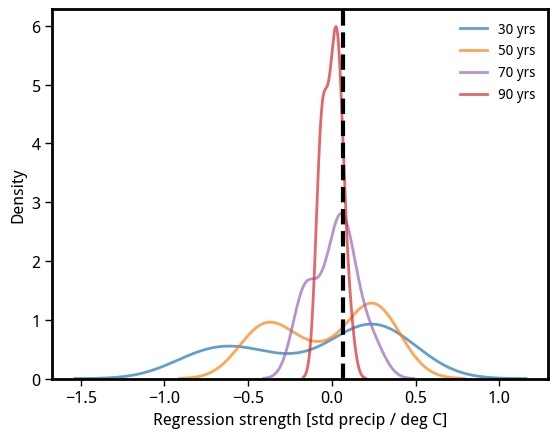

In [31]:
# sns.histplot(sl[dur==30], element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='30 yrs')
# sns.histplot(sl[dur==50], element='step', kde=True, bins=31, alpha=0.3, color='tab:orange', label='50 yrs')
# sns.histplot(sl[dur==70], element='step', kde=True, bins=31, alpha=0.3, color='tab:purple', label='70 yrs')
# sns.histplot(sl[dur==90], element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='90 yrs')
# plt.axvline(sl[dur==100], color='k', ls='--', lw=3.0)

sns.kdeplot(sl[dur==30], alpha=0.7, lw=2.0, color='tab:blue', label='30 yrs')
sns.kdeplot(sl[dur==50], alpha=0.7, lw=2.0, color='tab:orange', label='50 yrs')
sns.kdeplot(sl[dur==70], alpha=0.7, lw=2.0, color='tab:purple', label='70 yrs')
sns.kdeplot(sl[dur==90], alpha=0.7, lw=2.0, color='tab:red', label='90 yrs')
plt.axvline(sl[dur==114], color='k', ls='--', lw=3.0)
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [std precip / deg C]')
# plt.title('N. Australia [OBS]')

plt.savefig('./images/method/ssa_reg_sample_size_effects.png', dpi=300, bbox_inches='tight')

In [32]:
np.std(sl[dur==30]), np.std(sl[dur==90])

(0.44124912684233575, 0.05226098065834452)

In [33]:
np.shape(sl[dur==30])

(43,)

In [34]:
np.max(sl[dur==30]), np.min(sl[dur==30])

(0.5270673207523091, -0.9027294242507429)

In [35]:
def calc_tele_diversity(precip_std, nino34, duration=30, gap=2):
    if np.nansum(precip_std) != 0:
        i = 0
        regr_arr = []
        pval_arr = []
        ey=[]
        while i < (len(precip_std.time) - duration):
            regr_arr.append(funcs.get_regr(nino34.isel(time = slice(i,i+duration)), precip_std.isel(time=slice(i,i+duration)), dim='time').data)
            pval_arr.append(funcs.get_pval(nino34.isel(time = slice(i,i+duration)), precip_std.isel(time=slice(i,i+duration)), dim='time').data)
            ey.append(float(nino34.time.dt.year[i+duration]))
            print(f'Completed ey: {float(nino34.time.dt.year[i+duration])}', end='\r')
            i += gap

        out30 = xr.Dataset(
            data_vars=dict(
                regr=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in regr_arr])),
                pval=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in pval_arr])),
            ),
            coords=dict(
                lon = ("lon", precip_std.lon.to_numpy()),
                lat = ("lat", precip_std.lat.to_numpy()),
                ey = ("ey", ey),
            ),
            )

        return out30

In [36]:
# precip_obs_det = funcs.detrend_separate_check(precip_obs_anom, dim='time', period=15)
precip_obs_det = precip_obs_anom - precip_obs_anom.rolling(time=9).mean('time')
precip_obs_std = precip_obs_det/precip_obs_det.std()

In [37]:
ts_obs_det = ts_obs_anom.bfill('time').resample(time='AS-JUN').mean('time') - ts_obs_anom.bfill('time').resample(time='AS-JUN').mean('time').rolling(time=15).mean('time')

In [38]:
precip_rean_anom = funcs.calc_anom(precip_rean, precip_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')

In [39]:
# precip_rean_det = funcs.detrend_separate_check(precip_rean_anom, dim='time', period=15)
precip_rean_det = precip_rean_anom - precip_rean_anom.rolling(time=15).mean('time')
precip_rean_std = precip_rean_det/precip_rean_det.std()

In [40]:
precip_obs_std = precip_obs_std.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
precip_obs_std['time'] = nino34_obs['time']

In [41]:
ts_obs_det = ts_obs_det.sel(time = slice('1900', '2014'))
# nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
ts_obs_det['time'] = nino34_obs['time']

In [42]:
precip_rean_std = precip_rean_std.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
precip_rean_std['time'] = nino34_obs['time']

In [43]:
long_regr = funcs.get_regr(nino34_obs, precip_obs_std, dim='time')
long_pval = funcs.get_pval(nino34_obs, precip_obs_std, dim='time')

In [44]:
long_regr_ts = funcs.get_regr(nino34_obs, ts_obs_det, dim='time')
long_pval_ts = funcs.get_pval(nino34_obs, ts_obs_det, dim='time')

In [45]:
long_regr_rean = funcs.get_regr(nino34_obs, precip_rean_std.prate, dim='time')
long_pval_rean = funcs.get_pval(nino34_obs, precip_rean_std.prate, dim='time')

In [46]:
# out30 = calc_tele_diversity(precip_obs_std, nino34_obs, duration=30, gap=2)

In [47]:
# out30_rean = calc_tele_diversity(precip_rean_std.prate, nino34_obs, duration=30, gap=2)

In [48]:
# out30_ts = calc_tele_diversity(ts_obs_det, nino34_obs, duration=30, gap=2)

In [49]:
# out30.to_netcdf('./data/out30_sondjf.nc')

In [50]:
# out30_rean.to_netcdf('./data/out30_rean.nc')

In [51]:
# out30_ts.to_netcdf('./data/out30_ts.nc')

In [52]:
out30 = xr.open_dataset('./data/out30.nc')
out30_sondjf = xr.open_dataset('./data/out30_sondjf.nc')
out30_ts = xr.open_dataset('./data/out30_ts.nc')
out30_rean = xr.open_dataset('./data/out30_rean.nc')

<GeoAxesSubplot:title={'center':'ENSO-rainfall teleconnection [1900 - 2014]'}, xlabel='lon', ylabel='lat'>

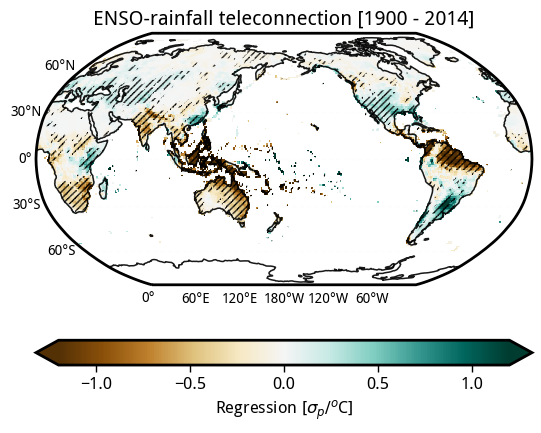

In [ ]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval.lon, long_pval.lat)
zz = np.ma.masked_greater_equal(long_pval.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('ENSO-rainfall teleconnection [1900 - 2014]')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

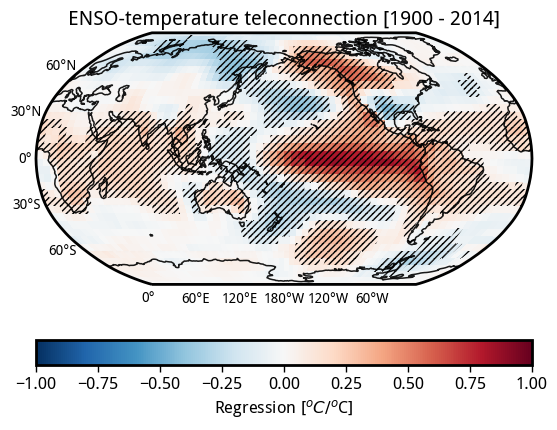

In [54]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_ts.plot(vmin=-1.0, cmap='RdBu_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$^{o}C/^{o}$C]'))
xx, yy = np.meshgrid(long_pval_ts.lon, long_pval_ts.lat)
zz = np.ma.masked_greater_equal(long_pval_ts.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('ENSO-temperature teleconnection [1900 - 2014]')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
plt.savefig('./images/long_regr_ts.png', dpi=300, bbox_inches='tight')

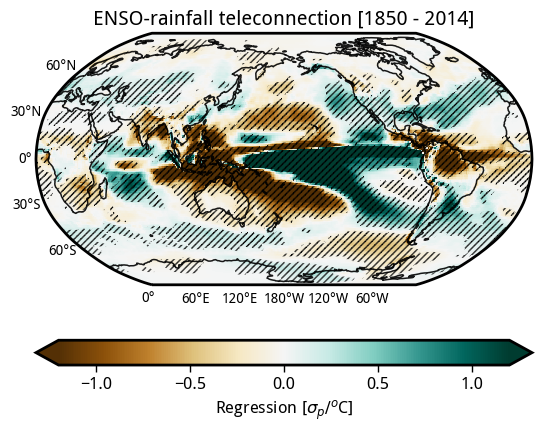

In [109]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_rean.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval_rean.lon, long_pval_rean.lat)
zz = np.ma.masked_greater_equal(long_pval_rean.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('ENSO-rainfall teleconnection [1850 - 2014]')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
plt.savefig('./images/long_regr_rean.png', dpi=300, bbox_inches='tight')

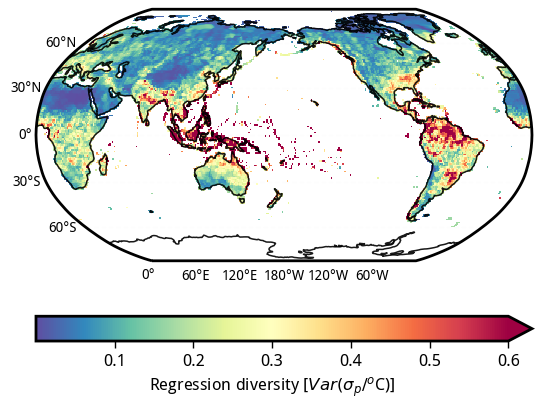

In [55]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30.regr.std('ey').plot(vmax=0.6, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(\sigma_{p}/^{o}$C)]'))
plot_background(ax)
plt.savefig('./images/variance_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

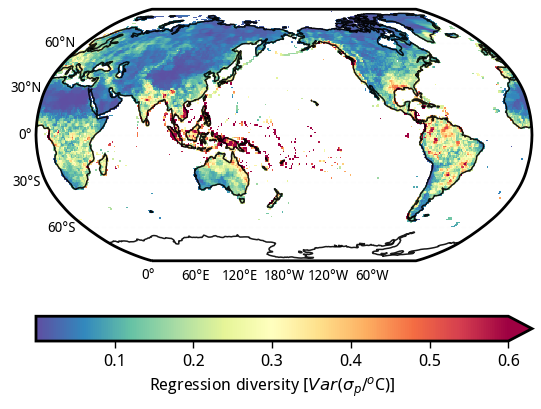

In [56]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_sondjf.regr.std('ey').plot(vmax=0.6, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(\sigma_{p}/^{o}$C)]'))
plot_background(ax)
# plt.savefig('./images/variance_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

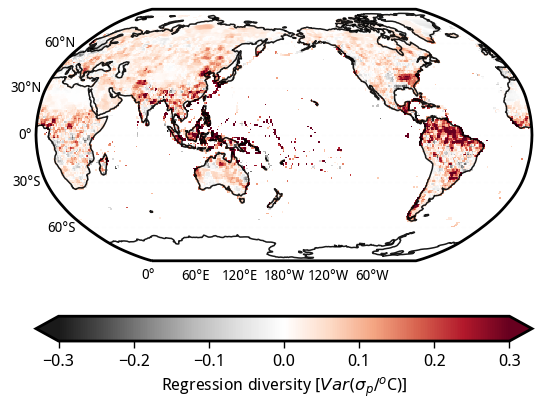

In [74]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30.regr.std('ey') - out30_sondjf.regr.std('ey')).plot(vmin=-0.3, cmap='RdGy_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(\sigma_{p}/^{o}$C)]'))
plot_background(ax)
# plt.savefig('./images/variance_regr_30y.png', dpi=300, bbox_inches='tight')

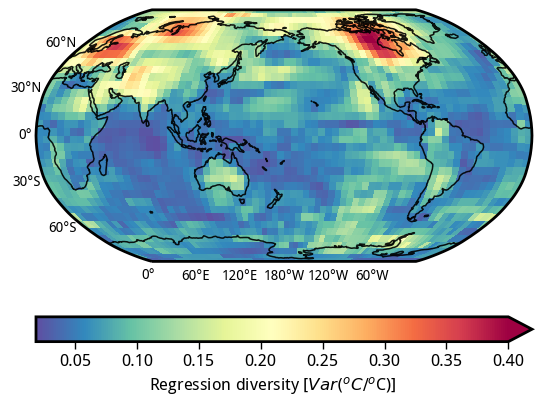

In [65]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_ts.regr.std('ey').plot(vmax=0.4, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(^{o}C/^{o}$C)]'))
plot_background(ax)
plt.savefig('./images/variance_regr_30y_ts.png', dpi=300, bbox_inches='tight')

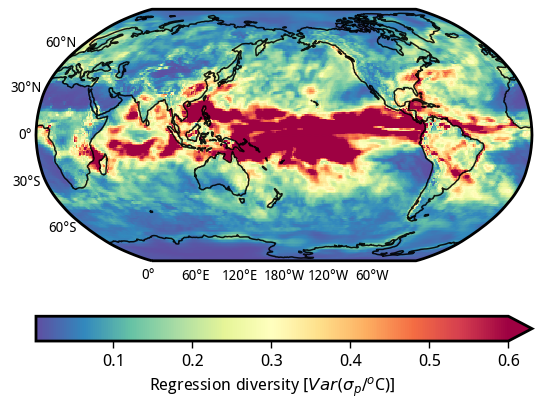

In [33]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_rean.regr.std('ey').plot(vmax=0.6, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(\sigma_{p}/^{o}$C)]'))
plot_background(ax)
plt.savefig('./images/variance_regr_30y_rean.png', dpi=300, bbox_inches='tight')

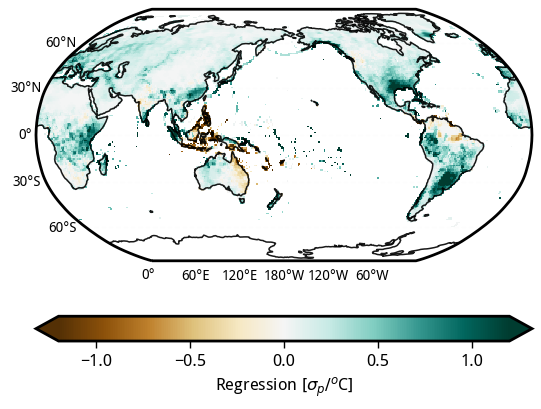

In [46]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30.regr.max('ey').plot(vmax=1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/max_regr_30y.png', dpi=300, bbox_inches='tight')

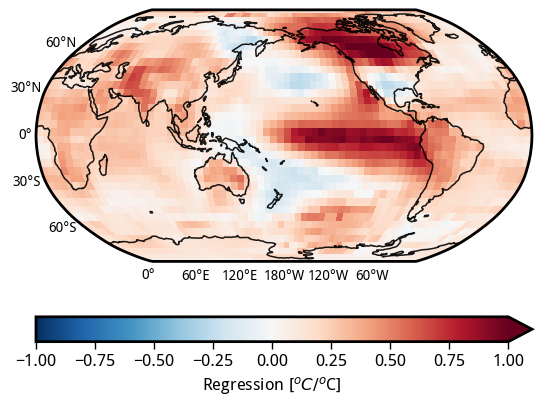

In [67]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_ts.regr.max('ey').plot(vmax=1.0, cmap='RdBu_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$^{o}C/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/max_regr_30y_ts.png', dpi=300, bbox_inches='tight')

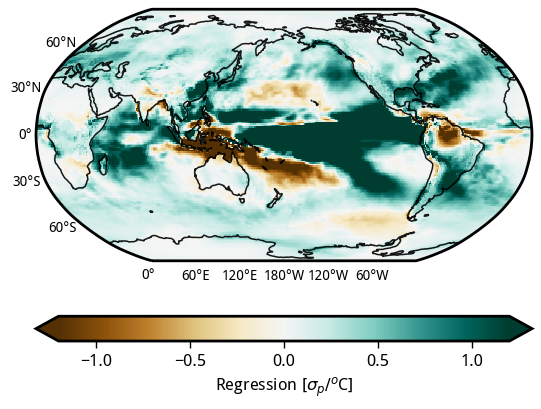

In [113]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_rean.regr.max('ey').plot(vmax=1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/max_regr_30y_rean.png', dpi=300, bbox_inches='tight')

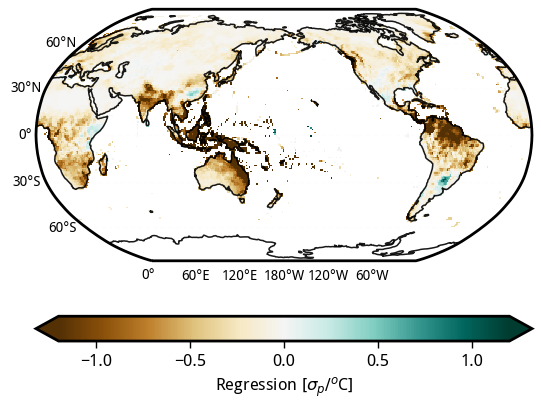

In [47]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30.regr.min('ey').plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/min_regr_30y.png', dpi=300, bbox_inches='tight')

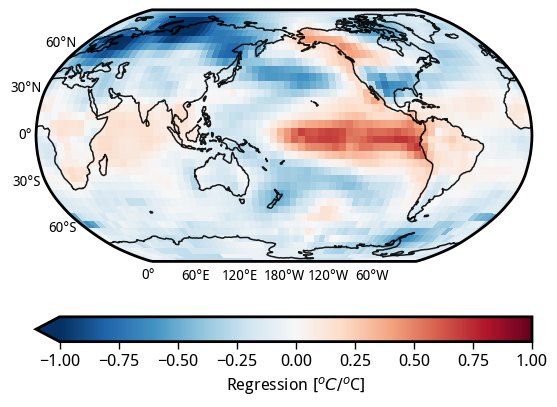

In [69]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_ts.regr.min('ey').plot(vmin=-1.0, cmap='RdBu_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$^{o}C/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/min_regr_30y_ts.png', dpi=300, bbox_inches='tight')

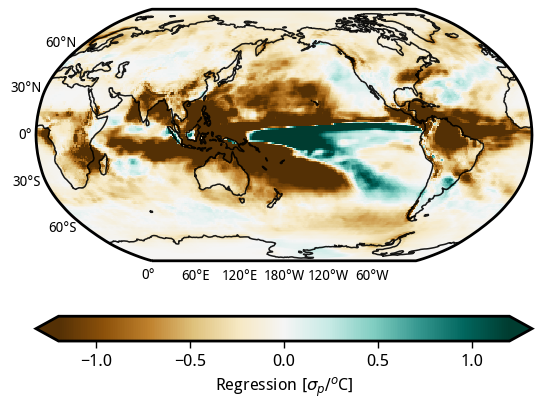

In [121]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_rean.regr.min('ey').plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/min_regr_30y_rean.png', dpi=300, bbox_inches='tight')

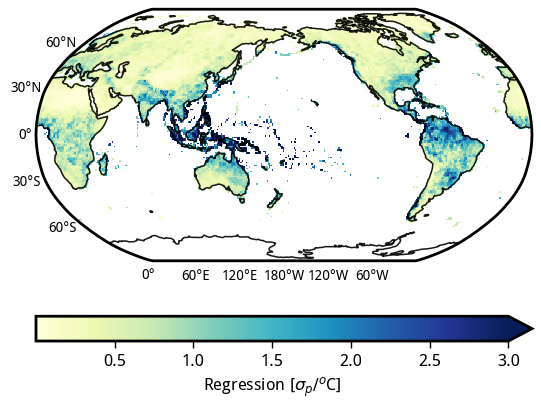

In [124]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30.regr.max('ey') - out30.regr.min('ey')).plot(vmax=3, cmap='YlGnBu', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

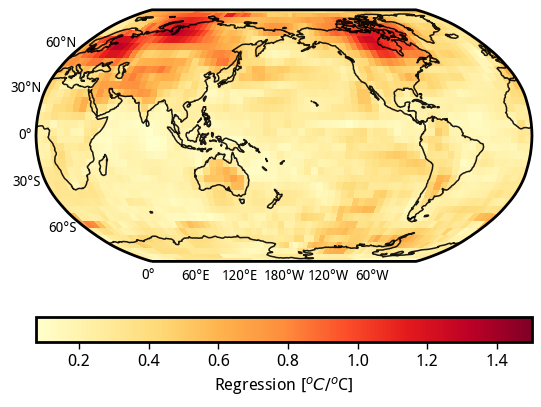

In [74]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_ts.regr.max('ey') - out30_ts.regr.min('ey')).plot(vmax=1.5, cmap='YlOrRd', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$^{o}C/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/range_regr_30y_ts.png', dpi=300, bbox_inches='tight')

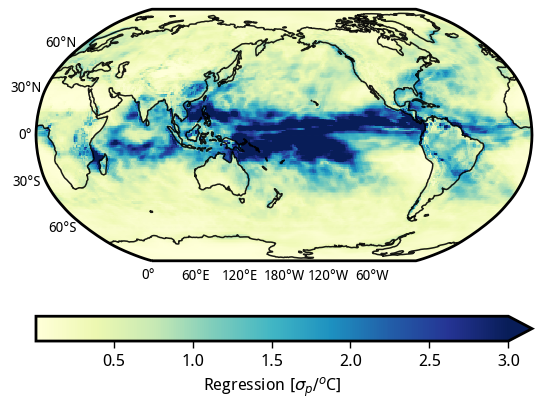

In [125]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_rean.regr.max('ey') - out30_rean.regr.min('ey')).plot(vmax=3, cmap='YlGnBu', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/range_regr_30y_rean.png', dpi=300, bbox_inches='tight')

In [ ]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(long_regr/out30.regr.std('ey')).plot(vmin=-3.0, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
plt.savefig('./images/long_regr_location_context_ts.png', dpi=300, bbox_inches='tight')

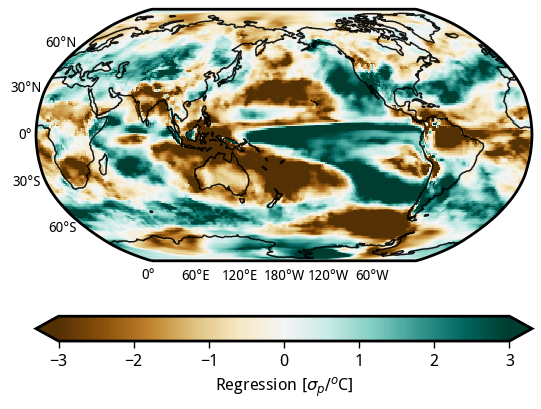

In [127]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(long_regr_rean/out30_rean.regr.std('ey')).plot(vmin=-3.0, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/long_regr_location_context_rean.png', dpi=300, bbox_inches='tight')

#### Potential TODOs


- breaking this thing down to regions and plotting the max, min, std and context for each IPCC region to get more ideas on a regional context

#### The plot below highlights that the ENSO-rainfall variabilty on shorter term is remarkably similar to the local rainfall variability

ENSO is perhaps a key factor responsible for long term rainfall variability in these key regions

<GeoAxesSubplot:xlabel='Longitude [degrees_east]', ylabel='Latitude [degrees_north]'>

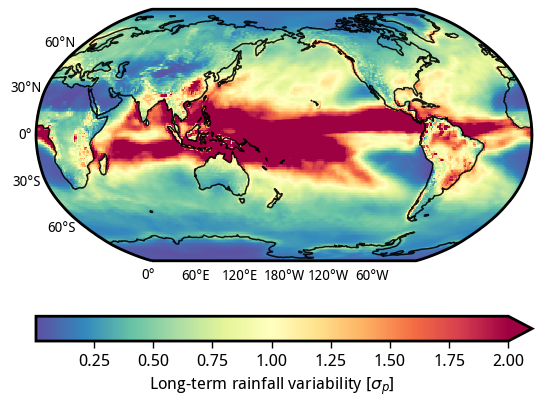

In [280]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(precip_rean_std.prate.std('time')).plot(vmax=2, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Long-term rainfall variability [$\sigma_{p}$]'))
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

**Timing of the peaks**

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

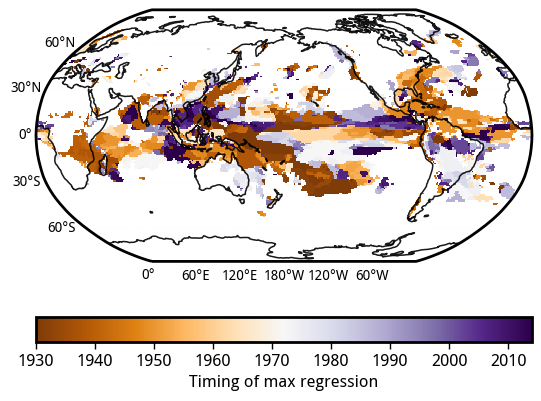

In [80]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_rean.regr.ey.where((out30_rean.regr == out30_rean.regr.min('ey')) & (out30_rean.regr.std('ey') > 0.20)).mean('ey')).plot(cmap='PuOr', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of max regression'), robust=True)
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

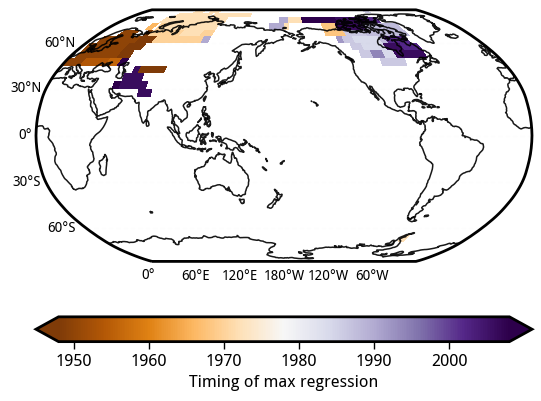

In [78]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_ts.regr.ey.where((out30_ts.regr == out30_ts.regr.min('ey')) & (out30_ts.regr.std('ey') > 0.20)).mean('ey')).plot(cmap='PuOr', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of max regression'), robust=True)
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

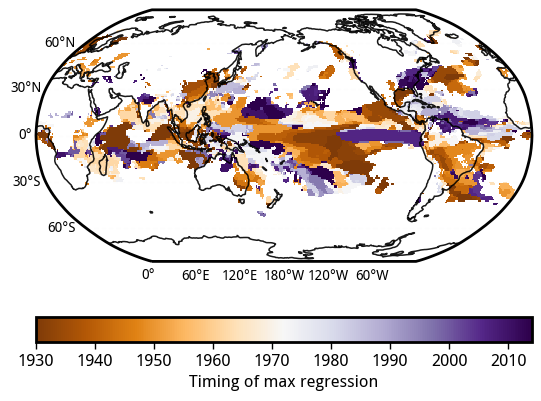

In [282]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_rean.regr.ey.where((out30_rean.regr == out30_rean.regr.max('ey')) & (out30_rean.regr.std('ey') > 0.20)).mean('ey')).plot(cmap='PuOr', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of max regression'), robust=True)
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

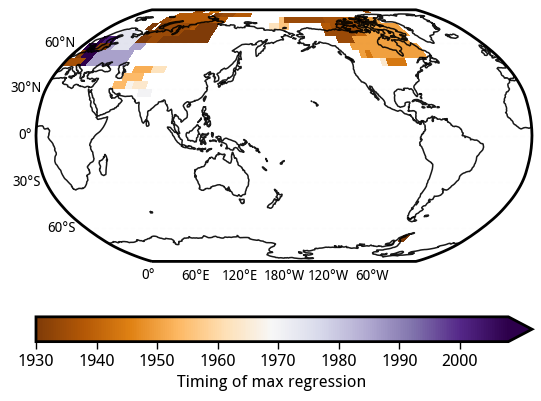

In [81]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30_ts.regr.ey.where((out30_ts.regr == out30_ts.regr.max('ey')) & (out30_ts.regr.std('ey') > 0.20)).mean('ey')).plot(cmap='PuOr', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of max regression'), robust=True)
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

In [82]:
def calc_windowed_tpi_strength(tpi_index, duration=30, gap=2):
    if np.nansum(tpi_index) != 0:
        i = 0
        tpi_out = []
        ey=[]
        while i < (len(tpi_index.time) - duration):
            tpi_out.append(tpi_index.isel(time=slice(i,i+duration)).mean('time').data)
            ey.append(float(tpi_index.time.dt.year[i+duration]))
            print(f'Completed ey: {float(tpi_index.time.dt.year[i+duration])}', end='\r')
            i += gap

        out = xr.Dataset(
            data_vars=dict(
                tpi=(["ey"], np.concatenate([arr[np.newaxis, ...] for arr in tpi_out])),
            ),
            coords=dict(
                ey = ("ey", ey),
            ),
            )

        return out

In [83]:
tpi_da = xr.open_dataset('./data/tpi.nc')
tpi_windows = calc_windowed_tpi_strength(tpi_da.TPI_unfil.resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')), duration=30, gap=2)

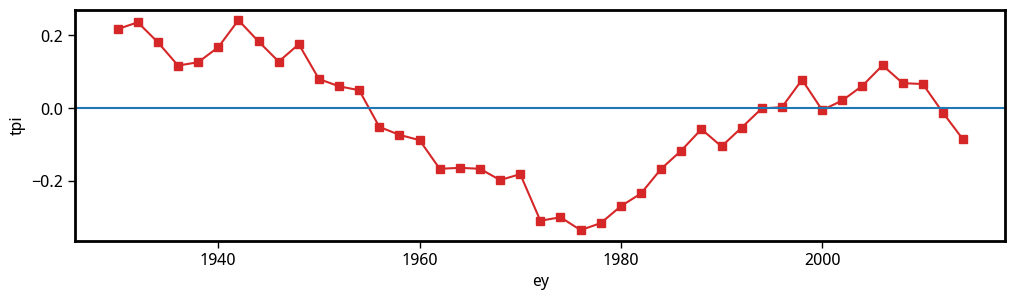

In [84]:
plt.figure(figsize=(12,3))
# (tpi_da.TPI_unfil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(color='k', alpha=0.1, lw=1.0)
# (tpi_da.TPI_fil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(lw=2.0, color='tab:red')
(tpi_windows.tpi).plot(marker='s', color='tab:red')
plt.axhline(0.0)

In [78]:
tpi_tele_corr = funcs.get_corr(tpi_windows.tpi, out30.regr, dim='ey')
tpi_tele_pval = funcs.get_pval(tpi_windows.tpi, out30.regr, dim='ey')

In [85]:
tpi_tele_corr = funcs.get_corr(tpi_windows.tpi, out30_ts.regr, dim='ey')
tpi_tele_pval = funcs.get_pval(tpi_windows.tpi, out30_ts.regr, dim='ey')

In [285]:
tpi_tele_corr = funcs.get_corr(tpi_windows.tpi, out30_rean.regr, dim='ey')
tpi_tele_pval = funcs.get_pval(tpi_windows.tpi, out30_rean.regr, dim='ey')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

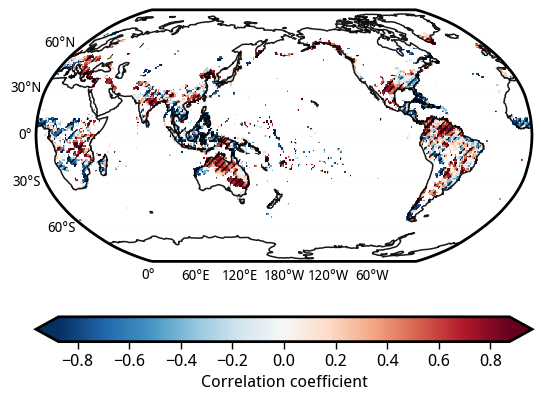

In [81]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(tpi_tele_corr.where((out30.regr.std('ey') > 0.20))).plot(cmap='RdBu_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Correlation coefficient'), robust=True)
xx, yy = np.meshgrid(tpi_tele_corr.lon, tpi_tele_corr.lat)
zz = np.ma.masked_greater_equal(tpi_tele_pval.where((out30.regr.std('ey') > 0.20)).data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

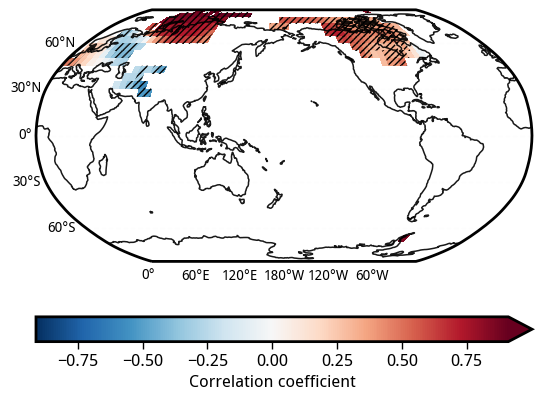

In [86]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(tpi_tele_corr.where((out30_ts.regr.std('ey') > 0.20))).plot(cmap='RdBu_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Correlation coefficient'), robust=True)
xx, yy = np.meshgrid(tpi_tele_corr.lon, tpi_tele_corr.lat)
zz = np.ma.masked_greater_equal(tpi_tele_pval.where((out30_ts.regr.std('ey') > 0.20)).data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

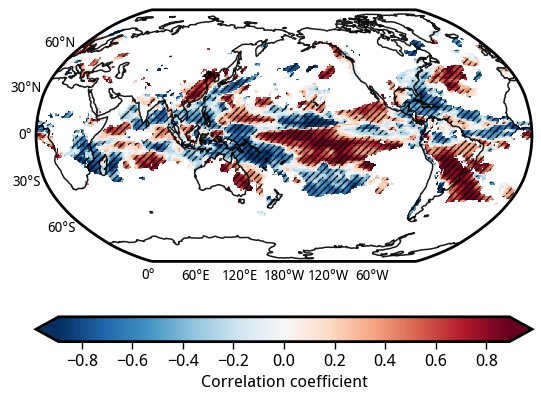

In [286]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(tpi_tele_corr.where((out30_rean.regr.std('ey') > 0.20))).plot(cmap='RdBu_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Correlation coefficient'), robust=True)
xx, yy = np.meshgrid(tpi_tele_corr.lon, tpi_tele_corr.lat)
zz = np.ma.masked_greater_equal(tpi_tele_pval.where((out30_rean.regr.std('ey') > 0.20)).data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

In [290]:
long_regr_rean_pre70 = funcs.get_regr(nino34_obs.sel(time = slice('1900', '1970')), precip_rean_std.prate.sel(time = slice('1900', '1970')), dim='time')
long_regr_rean_post80 = funcs.get_regr(nino34_obs.sel(time = slice('1980', '2014')), precip_rean_std.prate.sel(time = slice('1980', '2014')), dim='time')

In [291]:
long_pval_rean_pre70 = funcs.get_pval(nino34_obs.sel(time = slice('1900', '1970')), precip_rean_std.prate.sel(time = slice('1900', '1970')), dim='time')
long_pval_rean_post80 = funcs.get_pval(nino34_obs.sel(time = slice('1980', '2014')), precip_rean_std.prate.sel(time = slice('1980', '2014')), dim='time')

<GeoAxesSubplot:title={'center':'ENSO-rainfall teleconnection [1900 - 1970]'}, xlabel='lon', ylabel='lat'>

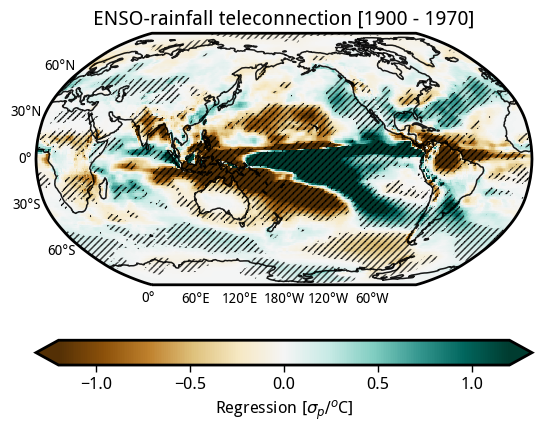

In [292]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_rean_pre70.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval_rean_pre70.lon, long_pval_rean_pre70.lat)
zz = np.ma.masked_greater_equal(long_pval_rean_pre70.data, 0.05)
ax.pcolor(xx, yy, zz, alpha=0., hatch='/////', transform=ccrs.PlateCarree())
plt.title('ENSO-rainfall teleconnection [1900 - 1970]')
plot_background(ax)

<GeoAxesSubplot:title={'center':'ENSO-rainfall teleconnection [1980 - 2014]'}, xlabel='lon', ylabel='lat'>

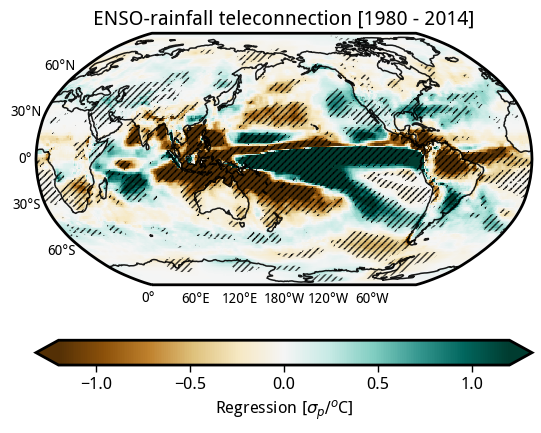

In [293]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_rean_post80.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
# xx, yy = np.meshgrid(long_pval_pre70.lon, long_pval_pre70.lat)
zz = np.ma.masked_greater_equal(long_pval_rean_post80.data, 0.05)
ax.pcolor(xx, yy, zz, alpha=0., hatch='/////', transform=ccrs.PlateCarree())
plt.title('ENSO-rainfall teleconnection [1980 - 2014]')
plot_background(ax)

<GeoAxesSubplot:title={'center':'Difference'}, xlabel='lon', ylabel='lat'>

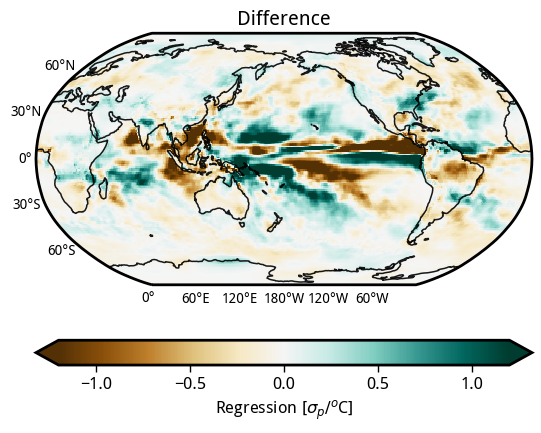

In [295]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(long_regr_rean_post80 - long_regr_rean_pre70).plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plt.title('Difference')
plot_background(ax)

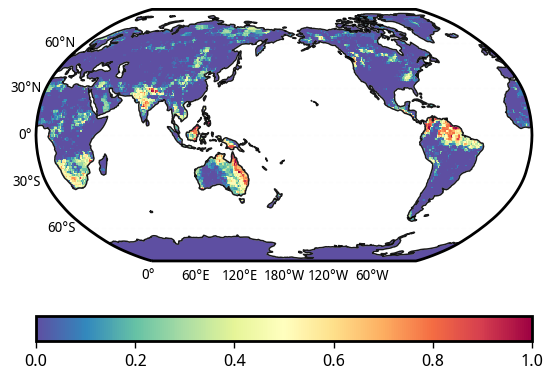

In [59]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30.regr.where((out30.regr < 0) & (out30.pval <= 0.05)).count('ey')/len(out30.regr.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

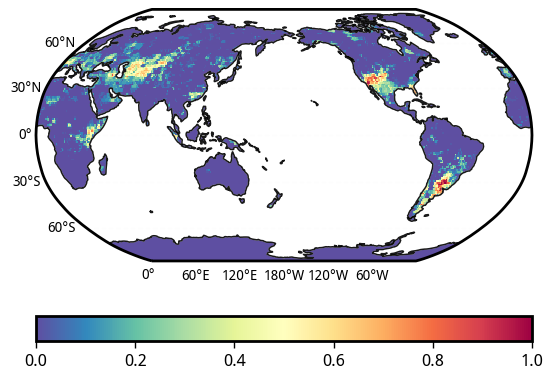

In [60]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30.regr.where((out30.regr > 0) & (out30.pval <= 0.05)).count('ey')/len(out30.regr.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

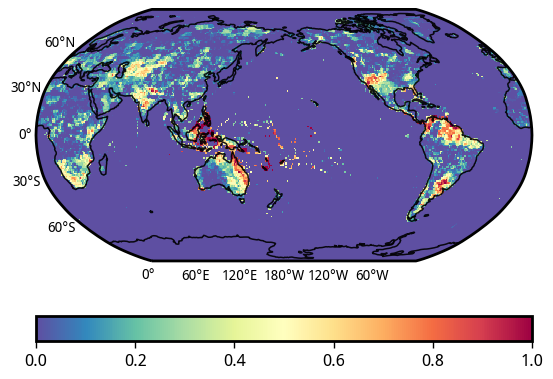

In [62]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30.pval.where((out30.pval <= 0.05)).count('ey')/len(out30.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

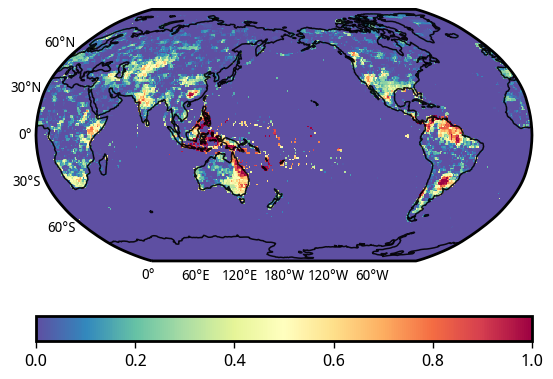

In [ ]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_sondjf.pval.where((out30_sondjf.pval <= 0.05)).count('ey')/len(out30_sondjf.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

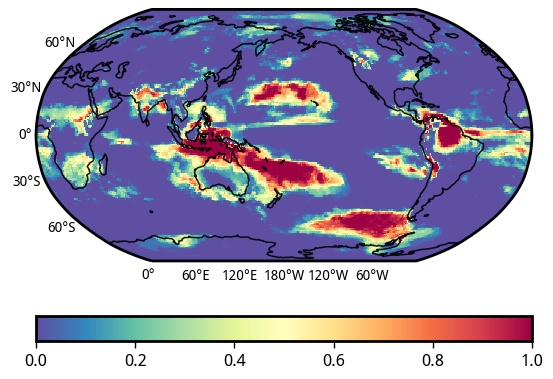

In [105]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_rean.regr.where((out30_rean.regr < 0) & (out30_rean.pval <= 0.05)).count('ey')/len(out30_rean.regr.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

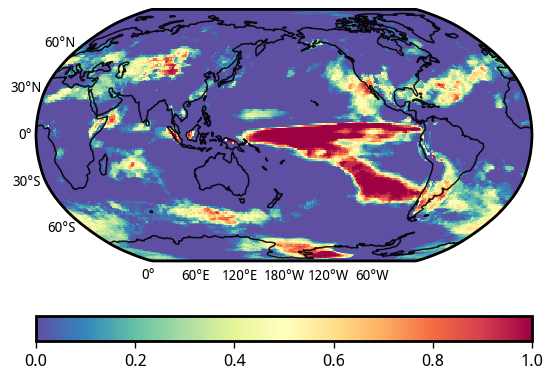

In [106]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_rean.regr.where((out30_rean.regr > 0) & (out30_rean.pval <= 0.05)).count('ey')/len(out30_rean.regr.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

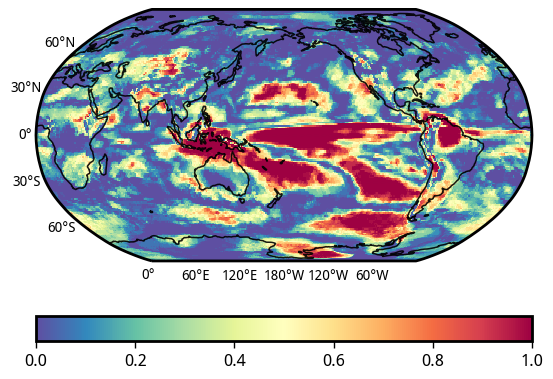

In [102]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_rean.pval.where((out30_rean.pval <= 0.05)).count('ey')/len(out30_rean.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

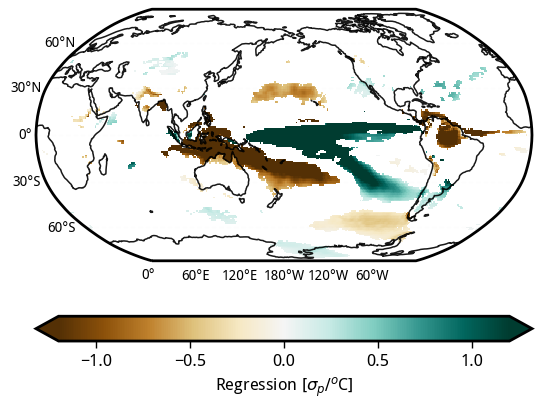

In [99]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_rean.pval.where((out30_rean.pval <= 0.05)).count('ey')/len(out30_rean.pval.ey))
long_regr_rean.where(ratio >= 0.6).plot(cmap='BrBG', vmin=-1.2, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

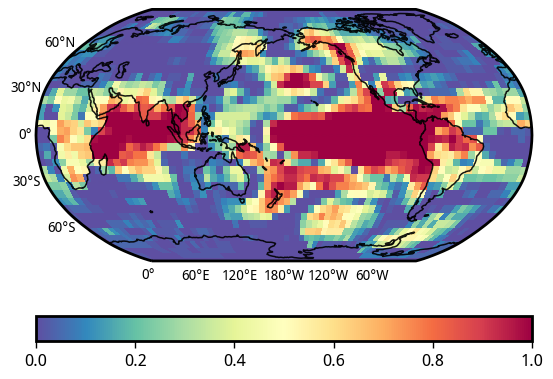

In [101]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_ts.regr.where((out30_ts.pval <= 0.05)).count('ey')/len(out30_ts.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:title={'center':'realization = 100'}, xlabel='lon', ylabel='lat'>

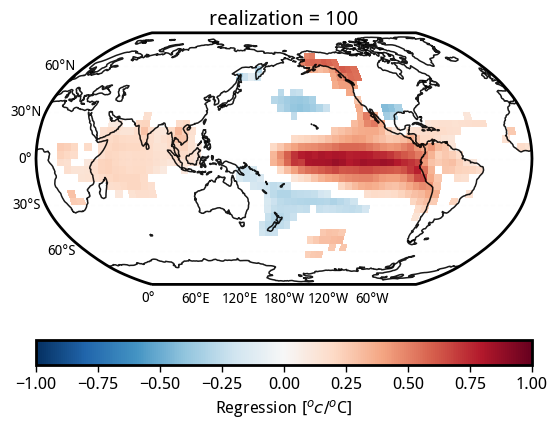

In [100]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_ts.pval.where((out30_ts.pval <= 0.05)).count('ey')/len(out30_ts.pval.ey))
long_regr_ts.where(ratio >= 0.6).plot(cmap='RdBu_r', vmin=-1.0, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$^{o}c/^{o}$C]'))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

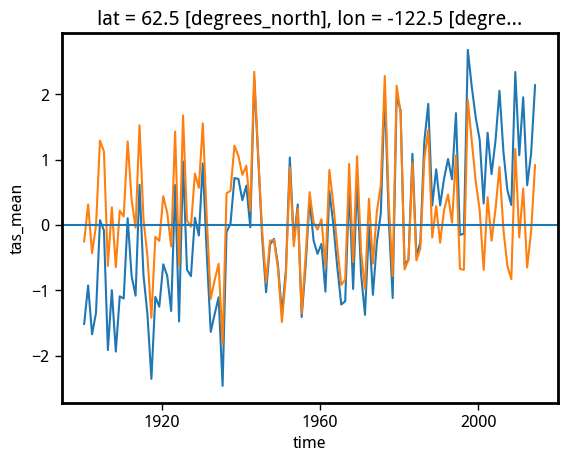

In [136]:
test1= ts_obs_anom.sel(lon = -125, lat = 60, method='nearest').bfill('time').resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014'))
test2 = ts_obs_det.sel(lon = -125, lat = 60, method='nearest')
test1['time'] = test2['time']
test1.plot()
test2.plot()

### using historical simulations and lens and cmip6 archive to illuminate the sample size problem

In [54]:
ts_cmip = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/ts_ssp5.nc').ts.sel(time = slice('1850', '2014'))
pr_cmip = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/CMIP6_models/pr_ssp5.nc').pr*86400*30).sel(time = slice('1850', '2014'))

In [55]:
ts_access = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_ts.nc').ts.sel(time = slice('1850', '2014'))
pr_access = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_pr.nc').pr*86400*30).sel(time = slice('1850', '2014'))

In [56]:
ts_canesm = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/CanESM5_ssp5_ts.nc').ts.sel(time = slice('1850', '2014'))
pr_canesm = (xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/CanESM5_ssp5_pr.nc').pr*86400*30).sel(time = slice('1850', '2014'))

In [57]:
weights_model = np.cos(np.deg2rad(ts_cmip.lat))

nino34_cmip = funcs.detrend_separate_check(ts_cmip.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), dim='time', period=15).load()

In [58]:
nino34_access = funcs.detrend_separate_check(ts_access.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), dim='time', period=15).load()

In [59]:
nino34_canesm = funcs.detrend_separate_check(ts_canesm.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_model).mean(('lat', 'lon')), dim='time', period=15).load()

In [60]:
land_mask_model = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_cmip)
ar6_mask_model = regionmask.defined_regions.ar6.land.mask_3D(land_mask_model)

In [61]:
pr_cmip_det = pr_cmip - pr_cmip.rolling(time=15).mean('time')
pr_cmip_std = pr_cmip_det/pr_cmip_det.std('time')

In [62]:
pr_access_det = pr_access - pr_access.rolling(time=15).mean('time')
pr_access_std = pr_access_det/pr_access_det.std('time')

In [63]:
pr_canesm_det = pr_canesm - pr_canesm.rolling(time=15).mean('time')
pr_canesm_std = pr_canesm_det/pr_canesm_det.std('time')

In [64]:
pr_access_std['model'] = nino34_access['model']
pr_canesm_std['model'] = nino34_canesm['model']
nino34_cmip = nino34_cmip.drop_sel(model='KIOST-ESM')
pr_cmip_std['model'] = nino34_cmip['model']

In [65]:
regr_access100 = funcs.get_regr(nino34_access.sel(time = slice('1900', '2014')), pr_access_std.sel(time = slice('1900', '2014')), dim='time')

In [92]:
regr_access30 = funcs.get_regr(nino34_access.sel(time = slice('1990', '2020')), pr_access_std.sel(time = slice('1990', '2020')), dim='time')

In [66]:
regr_canesm100 = funcs.get_regr(nino34_canesm.sel(time = slice('1900', '2014')), pr_canesm_std.sel(time = slice('1900', '2014')), dim='time')

In [67]:
regr_cmip100 = funcs.get_regr(nino34_cmip.sel(time = slice('1900', '2014')), pr_cmip_std.sel(time = slice('1900', '2014')), dim='time')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

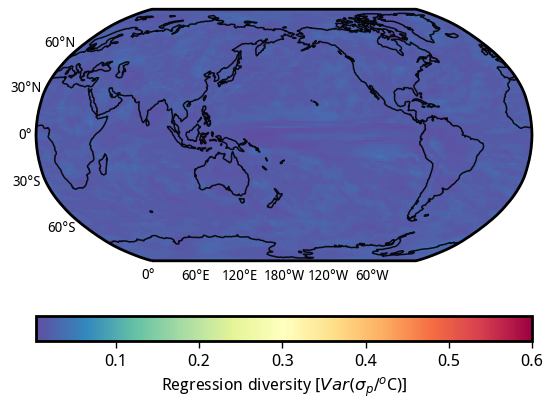

In [73]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
regr_access100.var('model').plot(vmax=0.6, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(\sigma_{p}/^{o}$C)]'))
plot_background(ax)

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

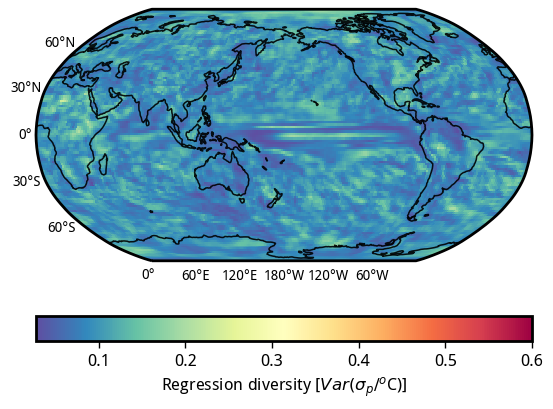

In [93]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
regr_access30.var('model').plot(vmax=0.6, cmap='Spectral_r', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression diversity [$Var(\sigma_{p}/^{o}$C)]'))
plot_background(ax)